In [24]:
import numpy as np
from tokenizers import Tokenizer
from collections import OrderedDict
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path
import itertools

root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1

In [25]:
dataset = load_dataset("cardiffnlp/tweet_eval", "stance_climate")

In [26]:
# feature representation

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vector = np.zeros(len(self))
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

class tfidf(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self.dataset = dataset['train']
        self.idf = self._compute_idf()

    def _compute_idf(self) -> 'np.array':
        num_documents = len(self.dataset)
        df = np.zeros(len(self.tokenizer.get_vocab()))

        for example in self.dataset:
            unique_token_ids = set(self.tokenizer.encode(example['text']).ids)
            for token_id in unique_token_ids:
                df[token_id] += 1

        idf = np.log((num_documents + 1) / (df + 1)) + 1
        return idf

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        tf_vector = np.zeros(len(self))
        token_ids = self.tokenizer.encode(x).ids

        for token_id in token_ids:
            tf_vector[token_id] += 1

        if len(token_ids) > 0:
            tf_vector /= len(token_ids)

        tfidf_vector = tf_vector * self.idf
        return tfidf_vector

In [27]:
#tokenizer
vocab_size = 1000
min_frequency = 2
corpus = [text for text in dataset["train"]["text"]]
tokenizer = Project1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
token_indicator_encoder = TokenIndicator(tokenizer)

In [28]:
# cross-validation
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [29]:
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

In [30]:
# classifiers
logistic_model = Project1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)



/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [31]:
outcome_space_abortion = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_atheism = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_climate = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_feminist = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_hillary = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])

In [32]:
classifiers = OrderedDict()

In [33]:
token_indicator_encoder = TokenIndicator(tokenizer)
bow_encoder = BagOfWords(tokenizer)
tfidf_encoder = tfidf(tokenizer)

In [34]:
classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    classifiers['logistic_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWar

In [35]:
classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    classifiers['mlp_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.078 seconds
Dataloader done! Time taken: 0.003 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0355 | train acc: 0.5000 | val loss: 1.0045 | val acc: 0.4930
Epoch 02 | train loss: 0.8850 | train acc: 0.7782 | val loss: 0.9544 | val acc: 0.4930
Epoch 03 | train loss: 0.7771 | train acc: 0.8415 | val loss: 0.9332 | val acc: 0.4507
Epoch 04 | train loss: 0.6897 | train acc: 0.7887 | val loss: 0.9308 | val acc: 0.4366
Epoch 05 | train loss: 0.6197 | train acc: 0.8028 | val loss: 0.9368 | val acc: 0.4507
Epoch 06 | train loss: 0.5474 | train acc: 0.8627 | val loss: 0.9359 | val acc: 0.4789
Epoch 07 | train loss: 0.4798 | train acc: 0.9225 | val loss: 0.9351 | val acc: 0.5211
Epoch 08 | train loss: 0.4112 | train acc: 0.9507 | val loss: 0.9374 | val acc: 0.5211
Epoch 09 | train loss: 0.3489 | train acc: 0.9577 | val loss: 0.9477 | val acc: 0.5352
Epoch 10 | train loss: 0.2875 | train acc: 0.9683 | val loss: 0.9548 | val acc: 0.5352
Epoch 11 | train loss: 0.2389 | train acc: 0.9718 | val loss: 0.9608 | val acc: 0.5493
Epoch 12 | train loss: 0.1968 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0808 | train acc: 0.3768 | val loss: 0.9872 | val acc: 0.6761
Epoch 02 | train loss: 0.9360 | train acc: 0.7430 | val loss: 0.8948 | val acc: 0.7183
Epoch 03 | train loss: 0.8334 | train acc: 0.8275 | val loss: 0.8136 | val acc: 0.7465
Epoch 04 | train loss: 0.7348 | train acc: 0.8838 | val loss: 0.7523 | val acc: 0.7465
Epoch 05 | train loss: 0.6505 | train acc: 0.8979 | val loss: 0.7068 | val acc: 0.7324
Epoch 06 | train loss: 0.5731 | train acc: 0.9296 | val loss: 0.6761 | val acc: 0.7324
Epoch 07 | train loss: 0.4986 | train acc: 0.9507 | val loss: 0.6570 | val acc: 0.7324
Epoch 08 | train loss: 0.4309 | train acc: 0.9507 | val loss: 0.6425 | val acc: 0.7183
Epoch 09 | train loss: 0.3705 | train acc: 0.9648 | val loss: 0.6277 | val acc: 0.7042
Epoch 10 | train loss: 0.3087 | train acc: 0.9613 | val loss: 0.6171 | val acc: 0.7183
Epoch 11 | train loss: 0.2586 | train acc: 0.9613 | val loss: 0.6098 | val acc: 0.7183
Epoch 12 | train loss: 0.2172 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1009 | train acc: 0.3169 | val loss: 1.0175 | val acc: 0.6197
Epoch 02 | train loss: 0.9461 | train acc: 0.6761 | val loss: 0.9219 | val acc: 0.5493
Epoch 03 | train loss: 0.8325 | train acc: 0.7007 | val loss: 0.8508 | val acc: 0.5493
Epoch 04 | train loss: 0.7387 | train acc: 0.7113 | val loss: 0.8040 | val acc: 0.5634
Epoch 05 | train loss: 0.6626 | train acc: 0.7852 | val loss: 0.7708 | val acc: 0.5775
Epoch 06 | train loss: 0.5948 | train acc: 0.8627 | val loss: 0.7437 | val acc: 0.6479
Epoch 07 | train loss: 0.5199 | train acc: 0.9014 | val loss: 0.7167 | val acc: 0.6761
Epoch 08 | train loss: 0.4582 | train acc: 0.9507 | val loss: 0.6936 | val acc: 0.7324
Epoch 09 | train loss: 0.3953 | train acc: 0.9577 | val loss: 0.6745 | val acc: 0.7324
Epoch 10 | train loss: 0.3351 | train acc: 0.9613 | val loss: 0.6626 | val acc: 0.7183
Epoch 11 | train loss: 0.2849 | train acc: 0.9613 | val loss: 0.6416 | val acc: 0.7606
Epoch 12 | train loss: 0.2373 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0624 | train acc: 0.4613 | val loss: 0.9681 | val acc: 0.5775
Epoch 02 | train loss: 0.9202 | train acc: 0.6690 | val loss: 0.8779 | val acc: 0.5634
Epoch 03 | train loss: 0.8178 | train acc: 0.7218 | val loss: 0.8091 | val acc: 0.5634
Epoch 04 | train loss: 0.7315 | train acc: 0.7570 | val loss: 0.7587 | val acc: 0.5493
Epoch 05 | train loss: 0.6627 | train acc: 0.7958 | val loss: 0.7192 | val acc: 0.5775
Epoch 06 | train loss: 0.5860 | train acc: 0.8415 | val loss: 0.6874 | val acc: 0.5915
Epoch 07 | train loss: 0.5149 | train acc: 0.8944 | val loss: 0.6607 | val acc: 0.6056
Epoch 08 | train loss: 0.4495 | train acc: 0.9331 | val loss: 0.6418 | val acc: 0.6056
Epoch 09 | train loss: 0.3823 | train acc: 0.9401 | val loss: 0.6295 | val acc: 0.6338
Epoch 10 | train loss: 0.3254 | train acc: 0.9507 | val loss: 0.6208 | val acc: 0.6479
Epoch 11 | train loss: 0.2694 | train acc: 0.9648 | val loss: 0.6182 | val acc: 0.6479
Epoch 12 | train loss: 0.2258 | train acc: 

In [36]:
classifiers['mlp2_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_indicator-enc/seed-{seed}"
    classifiers['mlp2_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.076 seconds
Dataloader done! Time taken: 0.004 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0999 | train acc: 0.3275 | val loss: 1.0485 | val acc: 0.5211
Epoch 02 | train loss: 0.9820 | train acc: 0.6690 | val loss: 0.9920 | val acc: 0.4507
Epoch 03 | train loss: 0.8685 | train acc: 0.5915 | val loss: 0.9580 | val acc: 0.4366
Epoch 04 | train loss: 0.7599 | train acc: 0.5669 | val loss: 0.9764 | val acc: 0.4366
Epoch 05 | train loss: 0.6812 | train acc: 0.6021 | val loss: 0.9992 | val acc: 0.4789
Epoch 06 | train loss: 0.5969 | train acc: 0.8521 | val loss: 1.0152 | val acc: 0.5352
Epoch 07 | train loss: 0.4860 | train acc: 0.9049 | val loss: 1.0459 | val acc: 0.5211
Epoch 08 | train loss: 0.3702 | train acc: 0.9225 | val loss: 1.0471 | val acc: 0.5775
Epoch 09 | train loss: 0.2545 | train acc: 0.9613 | val loss: 1.0509 | val acc: 0.5493
Epoch 10 | train loss: 0.1715 | train acc: 0.9648 | val loss: 1.1114 | val acc: 0.5634
Epoch 11 | train loss: 0.1129 | train acc: 0.9718 | val loss: 1.2241 | val acc: 0.5493
Epoch 12 | train loss: 0.0786 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0413 | train acc: 0.4577 | val loss: 0.9934 | val acc: 0.2958
Epoch 02 | train loss: 0.9355 | train acc: 0.4894 | val loss: 0.8897 | val acc: 0.3380
Epoch 03 | train loss: 0.8256 | train acc: 0.7042 | val loss: 0.7915 | val acc: 0.5775
Epoch 04 | train loss: 0.7299 | train acc: 0.8451 | val loss: 0.7097 | val acc: 0.7465
Epoch 05 | train loss: 0.6370 | train acc: 0.8592 | val loss: 0.6978 | val acc: 0.6620
Epoch 06 | train loss: 0.5232 | train acc: 0.9190 | val loss: 0.6671 | val acc: 0.6479
Epoch 07 | train loss: 0.3922 | train acc: 0.9366 | val loss: 0.6410 | val acc: 0.6761
Epoch 08 | train loss: 0.2796 | train acc: 0.9472 | val loss: 0.6504 | val acc: 0.6620
Epoch 09 | train loss: 0.1899 | train acc: 0.9472 | val loss: 0.6879 | val acc: 0.6479
Epoch 10 | train loss: 0.1305 | train acc: 0.9613 | val loss: 0.7240 | val acc: 0.6761
Epoch 11 | train loss: 0.0924 | train acc: 0.9683 | val loss: 0.8068 | val acc: 0.6620
Epoch 12 | train loss: 0.0696 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0310 | train acc: 0.5352 | val loss: 0.9775 | val acc: 0.5493
Epoch 02 | train loss: 0.9360 | train acc: 0.5352 | val loss: 0.8924 | val acc: 0.5493
Epoch 03 | train loss: 0.8293 | train acc: 0.5352 | val loss: 0.8226 | val acc: 0.5493
Epoch 04 | train loss: 0.7350 | train acc: 0.5528 | val loss: 0.7757 | val acc: 0.5634
Epoch 05 | train loss: 0.6423 | train acc: 0.7042 | val loss: 0.7414 | val acc: 0.5915
Epoch 06 | train loss: 0.5338 | train acc: 0.8908 | val loss: 0.7016 | val acc: 0.7465
Epoch 07 | train loss: 0.4057 | train acc: 0.9366 | val loss: 0.6646 | val acc: 0.7746
Epoch 08 | train loss: 0.2880 | train acc: 0.9507 | val loss: 0.6259 | val acc: 0.7746
Epoch 09 | train loss: 0.1955 | train acc: 0.9542 | val loss: 0.6206 | val acc: 0.7746
Epoch 10 | train loss: 0.1346 | train acc: 0.9542 | val loss: 0.6494 | val acc: 0.8028
Epoch 11 | train loss: 0.0960 | train acc: 0.9613 | val loss: 0.6832 | val acc: 0.8310
Epoch 12 | train loss: 0.0731 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0902 | train acc: 0.3028 | val loss: 1.0085 | val acc: 0.6479
Epoch 02 | train loss: 0.9713 | train acc: 0.6690 | val loss: 0.8827 | val acc: 0.5493
Epoch 03 | train loss: 0.8544 | train acc: 0.5986 | val loss: 0.7725 | val acc: 0.5070
Epoch 04 | train loss: 0.7735 | train acc: 0.5493 | val loss: 0.7189 | val acc: 0.5070
Epoch 05 | train loss: 0.7076 | train acc: 0.6514 | val loss: 0.6766 | val acc: 0.6761
Epoch 06 | train loss: 0.6163 | train acc: 0.8627 | val loss: 0.6468 | val acc: 0.7042
Epoch 07 | train loss: 0.5042 | train acc: 0.8873 | val loss: 0.6226 | val acc: 0.7042
Epoch 08 | train loss: 0.3807 | train acc: 0.9120 | val loss: 0.5993 | val acc: 0.6479
Epoch 09 | train loss: 0.2670 | train acc: 0.9472 | val loss: 0.5861 | val acc: 0.7183
Epoch 10 | train loss: 0.1879 | train acc: 0.9577 | val loss: 0.6022 | val acc: 0.7042
Epoch 11 | train loss: 0.1272 | train acc: 0.9648 | val loss: 0.6380 | val acc: 0.7183
Epoch 12 | train loss: 0.0907 | train acc: 

In [37]:
classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    classifiers['logistic_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={'max_iter': 100}
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/

In [38]:
classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    classifiers['mlp_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.078 seconds
Dataloader done! Time taken: 0.003 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0736 | train acc: 0.4225 | val loss: 1.0197 | val acc: 0.4930
Epoch 02 | train loss: 0.8975 | train acc: 0.7430 | val loss: 0.9640 | val acc: 0.4930
Epoch 03 | train loss: 0.7718 | train acc: 0.7782 | val loss: 0.9372 | val acc: 0.4789
Epoch 04 | train loss: 0.6791 | train acc: 0.7676 | val loss: 0.9303 | val acc: 0.4789
Epoch 05 | train loss: 0.5953 | train acc: 0.8310 | val loss: 0.9294 | val acc: 0.4648
Epoch 06 | train loss: 0.5186 | train acc: 0.8944 | val loss: 0.9257 | val acc: 0.4789
Epoch 07 | train loss: 0.4470 | train acc: 0.9437 | val loss: 0.9211 | val acc: 0.5493
Epoch 08 | train loss: 0.3792 | train acc: 0.9507 | val loss: 0.9228 | val acc: 0.5634
Epoch 09 | train loss: 0.3204 | train acc: 0.9542 | val loss: 0.9223 | val acc: 0.5775
Epoch 10 | train loss: 0.2734 | train acc: 0.9648 | val loss: 0.9236 | val acc: 0.5775
Epoch 11 | train loss: 0.2244 | train acc: 0.9718 | val loss: 0.9215 | val acc: 0.5915
Epoch 12 | train loss: 0.1853 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0796 | train acc: 0.3768 | val loss: 0.9778 | val acc: 0.6479
Epoch 02 | train loss: 0.9240 | train acc: 0.6549 | val loss: 0.8768 | val acc: 0.6620
Epoch 03 | train loss: 0.8178 | train acc: 0.7465 | val loss: 0.8008 | val acc: 0.6761
Epoch 04 | train loss: 0.7194 | train acc: 0.8275 | val loss: 0.7551 | val acc: 0.7606
Epoch 05 | train loss: 0.6421 | train acc: 0.8908 | val loss: 0.7249 | val acc: 0.7324
Epoch 06 | train loss: 0.5613 | train acc: 0.9190 | val loss: 0.7026 | val acc: 0.6761
Epoch 07 | train loss: 0.4929 | train acc: 0.9225 | val loss: 0.6842 | val acc: 0.6901
Epoch 08 | train loss: 0.4231 | train acc: 0.9437 | val loss: 0.6658 | val acc: 0.6761
Epoch 09 | train loss: 0.3607 | train acc: 0.9472 | val loss: 0.6481 | val acc: 0.6901
Epoch 10 | train loss: 0.3041 | train acc: 0.9507 | val loss: 0.6464 | val acc: 0.6479
Epoch 11 | train loss: 0.2587 | train acc: 0.9542 | val loss: 0.6561 | val acc: 0.6479
Epoch 12 | train loss: 0.2106 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0779 | train acc: 0.4120 | val loss: 0.9834 | val acc: 0.6197
Epoch 02 | train loss: 0.9242 | train acc: 0.7289 | val loss: 0.8926 | val acc: 0.6197
Epoch 03 | train loss: 0.8060 | train acc: 0.7535 | val loss: 0.8275 | val acc: 0.6197
Epoch 04 | train loss: 0.7135 | train acc: 0.7606 | val loss: 0.7839 | val acc: 0.6197
Epoch 05 | train loss: 0.6392 | train acc: 0.8134 | val loss: 0.7508 | val acc: 0.6620
Epoch 06 | train loss: 0.5601 | train acc: 0.8908 | val loss: 0.7262 | val acc: 0.6761
Epoch 07 | train loss: 0.4943 | train acc: 0.9190 | val loss: 0.7020 | val acc: 0.7183
Epoch 08 | train loss: 0.4289 | train acc: 0.9366 | val loss: 0.6836 | val acc: 0.7465
Epoch 09 | train loss: 0.3693 | train acc: 0.9577 | val loss: 0.6675 | val acc: 0.7465
Epoch 10 | train loss: 0.3138 | train acc: 0.9577 | val loss: 0.6568 | val acc: 0.7465
Epoch 11 | train loss: 0.2686 | train acc: 0.9577 | val loss: 0.6520 | val acc: 0.7465
Epoch 12 | train loss: 0.2196 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0511 | train acc: 0.5141 | val loss: 0.9659 | val acc: 0.5634
Epoch 02 | train loss: 0.9070 | train acc: 0.6866 | val loss: 0.8738 | val acc: 0.5634
Epoch 03 | train loss: 0.7971 | train acc: 0.7218 | val loss: 0.8005 | val acc: 0.5634
Epoch 04 | train loss: 0.7034 | train acc: 0.7500 | val loss: 0.7465 | val acc: 0.5775
Epoch 05 | train loss: 0.6209 | train acc: 0.8028 | val loss: 0.7034 | val acc: 0.5493
Epoch 06 | train loss: 0.5452 | train acc: 0.8768 | val loss: 0.6700 | val acc: 0.6338
Epoch 07 | train loss: 0.4768 | train acc: 0.9331 | val loss: 0.6419 | val acc: 0.6620
Epoch 08 | train loss: 0.4091 | train acc: 0.9437 | val loss: 0.6236 | val acc: 0.6338
Epoch 09 | train loss: 0.3494 | train acc: 0.9577 | val loss: 0.6113 | val acc: 0.6620
Epoch 10 | train loss: 0.2945 | train acc: 0.9577 | val loss: 0.6039 | val acc: 0.6761
Epoch 11 | train loss: 0.2441 | train acc: 0.9613 | val loss: 0.6004 | val acc: 0.6761
Epoch 12 | train loss: 0.2040 | train acc: 

In [39]:
classifiers['mlp2_bow-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_bow-enc/seed-{seed}"
    classifiers['mlp2_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.097 seconds
Dataloader done! Time taken: 0.004 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0652 | train acc: 0.4366 | val loss: 1.0225 | val acc: 0.4366
Epoch 02 | train loss: 0.9150 | train acc: 0.5704 | val loss: 0.9634 | val acc: 0.4366
Epoch 03 | train loss: 0.7909 | train acc: 0.5634 | val loss: 0.9747 | val acc: 0.4366
Epoch 04 | train loss: 0.7032 | train acc: 0.5704 | val loss: 1.0008 | val acc: 0.4366
Epoch 05 | train loss: 0.6278 | train acc: 0.7993 | val loss: 1.0044 | val acc: 0.4789
Epoch 06 | train loss: 0.5319 | train acc: 0.9261 | val loss: 1.0205 | val acc: 0.4789
Epoch 07 | train loss: 0.4112 | train acc: 0.9155 | val loss: 1.0230 | val acc: 0.5070
Epoch 08 | train loss: 0.2934 | train acc: 0.9577 | val loss: 1.0106 | val acc: 0.5352
Epoch 09 | train loss: 0.2019 | train acc: 0.9648 | val loss: 1.0491 | val acc: 0.5493
Epoch 10 | train loss: 0.1318 | train acc: 0.9683 | val loss: 1.1399 | val acc: 0.5211
Epoch 11 | train loss: 0.0853 | train acc: 0.9754 | val loss: 1.1737 | val acc: 0.5352
Epoch 12 | train loss: 0.0629 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0991 | train acc: 0.3134 | val loss: 1.0273 | val acc: 0.3662
Epoch 02 | train loss: 0.9786 | train acc: 0.6761 | val loss: 0.9063 | val acc: 0.6197
Epoch 03 | train loss: 0.8632 | train acc: 0.8169 | val loss: 0.7917 | val acc: 0.7183
Epoch 04 | train loss: 0.7691 | train acc: 0.7183 | val loss: 0.7140 | val acc: 0.7606
Epoch 05 | train loss: 0.6940 | train acc: 0.7007 | val loss: 0.6825 | val acc: 0.7324
Epoch 06 | train loss: 0.5919 | train acc: 0.8592 | val loss: 0.6774 | val acc: 0.6620
Epoch 07 | train loss: 0.4728 | train acc: 0.9120 | val loss: 0.6533 | val acc: 0.6620
Epoch 08 | train loss: 0.3441 | train acc: 0.9366 | val loss: 0.6297 | val acc: 0.6761
Epoch 09 | train loss: 0.2372 | train acc: 0.9437 | val loss: 0.6818 | val acc: 0.6479
Epoch 10 | train loss: 0.1622 | train acc: 0.9577 | val loss: 0.7130 | val acc: 0.6338
Epoch 11 | train loss: 0.1136 | train acc: 0.9648 | val loss: 0.7782 | val acc: 0.6197
Epoch 12 | train loss: 0.0806 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0704 | train acc: 0.4261 | val loss: 1.0035 | val acc: 0.4085
Epoch 02 | train loss: 0.9562 | train acc: 0.5669 | val loss: 0.9059 | val acc: 0.5070
Epoch 03 | train loss: 0.8431 | train acc: 0.6549 | val loss: 0.8251 | val acc: 0.5493
Epoch 04 | train loss: 0.7500 | train acc: 0.5986 | val loss: 0.7916 | val acc: 0.5493
Epoch 05 | train loss: 0.6826 | train acc: 0.6796 | val loss: 0.7754 | val acc: 0.5493
Epoch 06 | train loss: 0.5899 | train acc: 0.8415 | val loss: 0.7491 | val acc: 0.6901
Epoch 07 | train loss: 0.4791 | train acc: 0.9190 | val loss: 0.7116 | val acc: 0.7042
Epoch 08 | train loss: 0.3606 | train acc: 0.9331 | val loss: 0.6744 | val acc: 0.6901
Epoch 09 | train loss: 0.2519 | train acc: 0.9401 | val loss: 0.6482 | val acc: 0.7042
Epoch 10 | train loss: 0.1760 | train acc: 0.9542 | val loss: 0.6630 | val acc: 0.7042
Epoch 11 | train loss: 0.1179 | train acc: 0.9613 | val loss: 0.6755 | val acc: 0.6901
Epoch 12 | train loss: 0.0836 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0878 | train acc: 0.3768 | val loss: 1.0139 | val acc: 0.5211
Epoch 02 | train loss: 0.9687 | train acc: 0.5458 | val loss: 0.9003 | val acc: 0.5211
Epoch 03 | train loss: 0.8457 | train acc: 0.5423 | val loss: 0.8043 | val acc: 0.5211
Epoch 04 | train loss: 0.7582 | train acc: 0.5423 | val loss: 0.7393 | val acc: 0.5211
Epoch 05 | train loss: 0.6683 | train acc: 0.6338 | val loss: 0.6826 | val acc: 0.5634
Epoch 06 | train loss: 0.5739 | train acc: 0.8662 | val loss: 0.6443 | val acc: 0.6761
Epoch 07 | train loss: 0.4612 | train acc: 0.9296 | val loss: 0.6249 | val acc: 0.6761
Epoch 08 | train loss: 0.3450 | train acc: 0.9261 | val loss: 0.6199 | val acc: 0.6620
Epoch 09 | train loss: 0.2411 | train acc: 0.9507 | val loss: 0.6199 | val acc: 0.6761
Epoch 10 | train loss: 0.1705 | train acc: 0.9507 | val loss: 0.6438 | val acc: 0.6761
Epoch 11 | train loss: 0.1232 | train acc: 0.9577 | val loss: 0.6902 | val acc: 0.7042
Epoch 12 | train loss: 0.0940 | train acc: 

In [40]:
classifiers['logistic_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"
    classifiers['logistic_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=tfidf_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/mac/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/

In [41]:
classifiers['mlp_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_tfidf-enc/seed-{seed}"
    classifiers['mlp_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=tfidf(tokenizer),
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.078 seconds
Dataloader done! Time taken: 0.003 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1068 | train acc: 0.2711 | val loss: 1.0886 | val acc: 0.4648
Epoch 02 | train loss: 1.0767 | train acc: 0.4683 | val loss: 1.0694 | val acc: 0.4930
Epoch 03 | train loss: 1.0451 | train acc: 0.6796 | val loss: 1.0476 | val acc: 0.5775
Epoch 04 | train loss: 1.0085 | train acc: 0.8662 | val loss: 1.0233 | val acc: 0.5211
Epoch 05 | train loss: 0.9663 | train acc: 0.8908 | val loss: 0.9982 | val acc: 0.4789
Epoch 06 | train loss: 0.9210 | train acc: 0.7782 | val loss: 0.9747 | val acc: 0.4366
Epoch 07 | train loss: 0.8739 | train acc: 0.7183 | val loss: 0.9534 | val acc: 0.4225
Epoch 08 | train loss: 0.8257 | train acc: 0.6725 | val loss: 0.9363 | val acc: 0.4366
Epoch 09 | train loss: 0.7811 | train acc: 0.6585 | val loss: 0.9247 | val acc: 0.4366
Epoch 10 | train loss: 0.7382 | train acc: 0.6620 | val loss: 0.9162 | val acc: 0.4507
Epoch 11 | train loss: 0.7007 | train acc: 0.7148 | val loss: 0.9096 | val acc: 0.4366
Epoch 12 | train loss: 0.6619 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1207 | train acc: 0.0986 | val loss: 1.1228 | val acc: 0.2676
Epoch 02 | train loss: 1.0950 | train acc: 0.4683 | val loss: 1.0993 | val acc: 0.2958
Epoch 03 | train loss: 1.0701 | train acc: 0.4577 | val loss: 1.0726 | val acc: 0.3099
Epoch 04 | train loss: 1.0410 | train acc: 0.5211 | val loss: 1.0408 | val acc: 0.3380
Epoch 05 | train loss: 1.0051 | train acc: 0.6725 | val loss: 1.0045 | val acc: 0.4930
Epoch 06 | train loss: 0.9653 | train acc: 0.8556 | val loss: 0.9640 | val acc: 0.5775
Epoch 07 | train loss: 0.9232 | train acc: 0.9085 | val loss: 0.9224 | val acc: 0.6338
Epoch 08 | train loss: 0.8777 | train acc: 0.9261 | val loss: 0.8784 | val acc: 0.7042
Epoch 09 | train loss: 0.8351 | train acc: 0.9225 | val loss: 0.8405 | val acc: 0.7183
Epoch 10 | train loss: 0.7955 | train acc: 0.9085 | val loss: 0.8093 | val acc: 0.7042
Epoch 11 | train loss: 0.7541 | train acc: 0.9014 | val loss: 0.7807 | val acc: 0.7042
Epoch 12 | train loss: 0.7168 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0918 | train acc: 0.4437 | val loss: 1.0755 | val acc: 0.5493
Epoch 02 | train loss: 1.0637 | train acc: 0.6831 | val loss: 1.0507 | val acc: 0.5775
Epoch 03 | train loss: 1.0357 | train acc: 0.6373 | val loss: 1.0216 | val acc: 0.5493
Epoch 04 | train loss: 1.0022 | train acc: 0.6092 | val loss: 0.9886 | val acc: 0.5493
Epoch 05 | train loss: 0.9637 | train acc: 0.5775 | val loss: 0.9533 | val acc: 0.5493
Epoch 06 | train loss: 0.9234 | train acc: 0.5880 | val loss: 0.9171 | val acc: 0.5493
Epoch 07 | train loss: 0.8807 | train acc: 0.5704 | val loss: 0.8820 | val acc: 0.5493
Epoch 08 | train loss: 0.8403 | train acc: 0.5845 | val loss: 0.8505 | val acc: 0.5493
Epoch 09 | train loss: 0.8001 | train acc: 0.5915 | val loss: 0.8230 | val acc: 0.5493
Epoch 10 | train loss: 0.7644 | train acc: 0.6162 | val loss: 0.8001 | val acc: 0.5493
Epoch 11 | train loss: 0.7299 | train acc: 0.6268 | val loss: 0.7801 | val acc: 0.5493
Epoch 12 | train loss: 0.6958 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0836 | train acc: 0.5423 | val loss: 1.0738 | val acc: 0.5211
Epoch 02 | train loss: 1.0600 | train acc: 0.5423 | val loss: 1.0544 | val acc: 0.5211
Epoch 03 | train loss: 1.0360 | train acc: 0.5423 | val loss: 1.0315 | val acc: 0.5211
Epoch 04 | train loss: 1.0082 | train acc: 0.5423 | val loss: 1.0047 | val acc: 0.5211
Epoch 05 | train loss: 0.9764 | train acc: 0.5423 | val loss: 0.9743 | val acc: 0.5211
Epoch 06 | train loss: 0.9390 | train acc: 0.5423 | val loss: 0.9405 | val acc: 0.5211
Epoch 07 | train loss: 0.9002 | train acc: 0.5423 | val loss: 0.9056 | val acc: 0.5211
Epoch 08 | train loss: 0.8573 | train acc: 0.5458 | val loss: 0.8722 | val acc: 0.5211
Epoch 09 | train loss: 0.8177 | train acc: 0.5599 | val loss: 0.8398 | val acc: 0.5211
Epoch 10 | train loss: 0.7760 | train acc: 0.5775 | val loss: 0.8102 | val acc: 0.5211
Epoch 11 | train loss: 0.7363 | train acc: 0.6303 | val loss: 0.7842 | val acc: 0.5352
Epoch 12 | train loss: 0.6969 | train acc: 

In [42]:
classifiers['mlp2_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_tfidf-enc/seed-{seed}"
    classifiers['mlp2_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.077 seconds
Dataloader done! Time taken: 0.003 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0445 | train acc: 0.5739 | val loss: 1.0191 | val acc: 0.4225
Epoch 02 | train loss: 0.9258 | train acc: 0.6796 | val loss: 0.9596 | val acc: 0.4366
Epoch 03 | train loss: 0.8077 | train acc: 0.7077 | val loss: 0.9351 | val acc: 0.4507
Epoch 04 | train loss: 0.6963 | train acc: 0.6620 | val loss: 0.9653 | val acc: 0.4507
Epoch 05 | train loss: 0.6043 | train acc: 0.7887 | val loss: 0.9875 | val acc: 0.5493
Epoch 06 | train loss: 0.4857 | train acc: 0.9261 | val loss: 1.0061 | val acc: 0.5634
Epoch 07 | train loss: 0.3604 | train acc: 0.9437 | val loss: 1.0128 | val acc: 0.6056
Epoch 08 | train loss: 0.2497 | train acc: 0.9613 | val loss: 1.0366 | val acc: 0.5775
Epoch 09 | train loss: 0.1614 | train acc: 0.9718 | val loss: 1.0977 | val acc: 0.5775
Epoch 10 | train loss: 0.1056 | train acc: 0.9754 | val loss: 1.1677 | val acc: 0.5634
Epoch 11 | train loss: 0.0752 | train acc: 0.9754 | val loss: 1.2139 | val acc: 0.5493
Epoch 12 | train loss: 0.0562 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0654 | train acc: 0.4824 | val loss: 0.9844 | val acc: 0.6761
Epoch 02 | train loss: 0.9459 | train acc: 0.7042 | val loss: 0.8645 | val acc: 0.7183
Epoch 03 | train loss: 0.8264 | train acc: 0.7113 | val loss: 0.7586 | val acc: 0.7183
Epoch 04 | train loss: 0.7284 | train acc: 0.7359 | val loss: 0.6948 | val acc: 0.7465
Epoch 05 | train loss: 0.6340 | train acc: 0.8204 | val loss: 0.6573 | val acc: 0.7465
Epoch 06 | train loss: 0.5249 | train acc: 0.9155 | val loss: 0.6565 | val acc: 0.6479
Epoch 07 | train loss: 0.4031 | train acc: 0.9225 | val loss: 0.6178 | val acc: 0.6901
Epoch 08 | train loss: 0.2936 | train acc: 0.9331 | val loss: 0.5998 | val acc: 0.7183
Epoch 09 | train loss: 0.2117 | train acc: 0.9437 | val loss: 0.6687 | val acc: 0.6761
Epoch 10 | train loss: 0.1497 | train acc: 0.9507 | val loss: 0.7198 | val acc: 0.6901
Epoch 11 | train loss: 0.1084 | train acc: 0.9577 | val loss: 0.7727 | val acc: 0.7042
Epoch 12 | train loss: 0.0859 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0652 | train acc: 0.5211 | val loss: 1.0071 | val acc: 0.5493
Epoch 02 | train loss: 0.9584 | train acc: 0.5387 | val loss: 0.9178 | val acc: 0.5493
Epoch 03 | train loss: 0.8536 | train acc: 0.5387 | val loss: 0.8372 | val acc: 0.5493
Epoch 04 | train loss: 0.7646 | train acc: 0.5458 | val loss: 0.8018 | val acc: 0.5493
Epoch 05 | train loss: 0.6890 | train acc: 0.6092 | val loss: 0.7895 | val acc: 0.5634
Epoch 06 | train loss: 0.5998 | train acc: 0.8627 | val loss: 0.7704 | val acc: 0.6056
Epoch 07 | train loss: 0.4932 | train acc: 0.9049 | val loss: 0.7429 | val acc: 0.6338
Epoch 08 | train loss: 0.3723 | train acc: 0.9190 | val loss: 0.7241 | val acc: 0.6620
Epoch 09 | train loss: 0.2637 | train acc: 0.9331 | val loss: 0.6851 | val acc: 0.7042
Epoch 10 | train loss: 0.1789 | train acc: 0.9472 | val loss: 0.7007 | val acc: 0.7324
Epoch 11 | train loss: 0.1210 | train acc: 0.9613 | val loss: 0.7399 | val acc: 0.7042
Epoch 12 | train loss: 0.0868 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0086 | train acc: 0.5141 | val loss: 0.9336 | val acc: 0.5211
Epoch 02 | train loss: 0.9053 | train acc: 0.5423 | val loss: 0.8378 | val acc: 0.5211
Epoch 03 | train loss: 0.8062 | train acc: 0.5458 | val loss: 0.7595 | val acc: 0.5211
Epoch 04 | train loss: 0.7242 | train acc: 0.5739 | val loss: 0.7063 | val acc: 0.5352
Epoch 05 | train loss: 0.6449 | train acc: 0.7746 | val loss: 0.6608 | val acc: 0.6197
Epoch 06 | train loss: 0.5366 | train acc: 0.8838 | val loss: 0.6327 | val acc: 0.6479
Epoch 07 | train loss: 0.4161 | train acc: 0.9014 | val loss: 0.6189 | val acc: 0.6479
Epoch 08 | train loss: 0.3034 | train acc: 0.9261 | val loss: 0.6096 | val acc: 0.6761
Epoch 09 | train loss: 0.2099 | train acc: 0.9401 | val loss: 0.6269 | val acc: 0.6901
Epoch 10 | train loss: 0.1472 | train acc: 0.9542 | val loss: 0.6665 | val acc: 0.6901
Epoch 11 | train loss: 0.1087 | train acc: 0.9542 | val loss: 0.7062 | val acc: 0.7042
Epoch 12 | train loss: 0.0845 | train acc: 

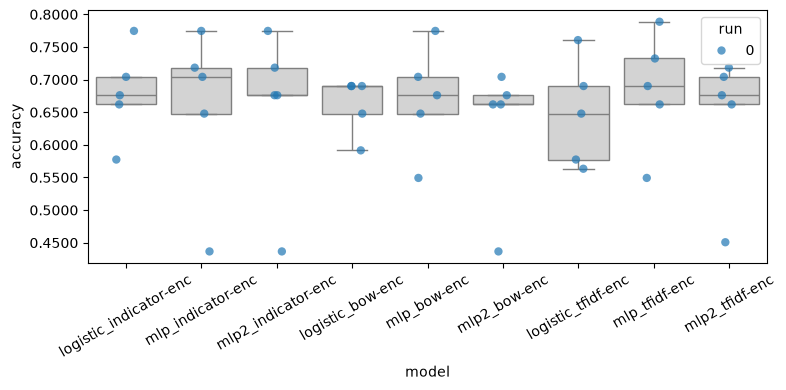

In [43]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(classifiers))

In [44]:
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])


A = logistic_indicator-enc, B = mlp_indicator-enc
P(A wins) = 0.5948
P(Tie)    = 0.1340
P(B wins) = 0.2712
Effect Size = -0.46

A = logistic_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.5975
P(Tie)    = 0.1369
P(B wins) = 0.2656
Effect Size = -0.47

A = mlp_indicator-enc, B = mlp2_indicator-enc
P(A wins) = 0.3743
P(Tie)    = 0.2514
P(B wins) = 0.3743
Effect Size = 0.00


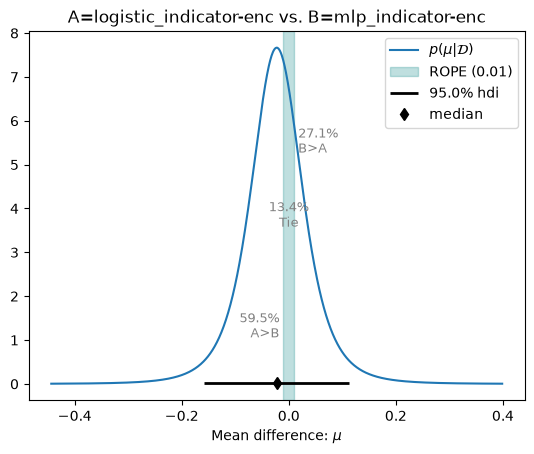

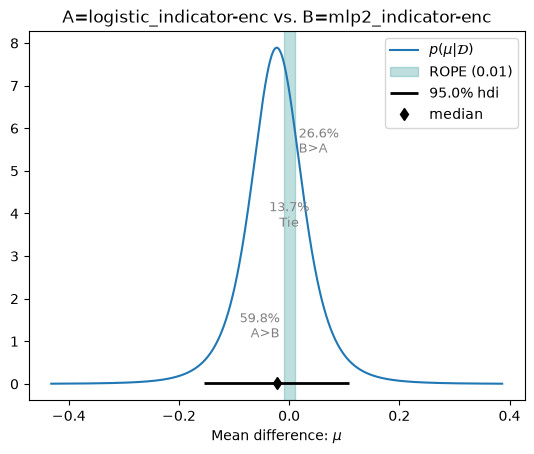

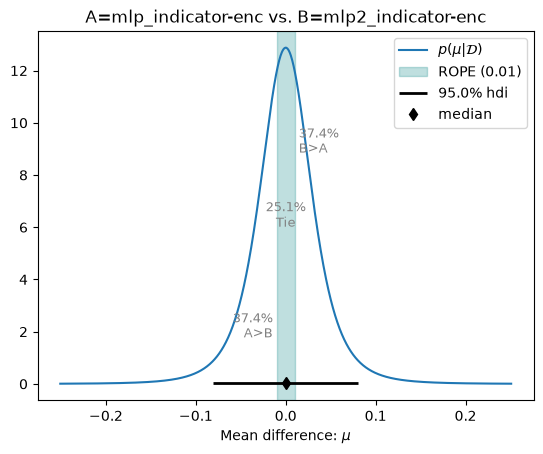

In [45]:
models = {
    "logistic_indicator-enc": get_all_measurements_for(
        classifiers, "logistic_indicator-enc"
    ).flatten(),

    "mlp_indicator-enc": get_all_measurements_for(
        classifiers, "mlp_indicator-enc"
    ).flatten(),

    "mlp2_indicator-enc": get_all_measurements_for(
        classifiers, "mlp2_indicator-enc"
    ).flatten()
}

rope = 0.01

# Compare every pair of models
for name_a, name_b in itertools.combinations(models.keys(), 2):

    posterior = Project1.analysis.BenavoliCorrelatedT(
        models[name_a],
        models[name_b],
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(rope)

    print(f"\nA = {name_a}, B = {name_b}")
    print(f"P(A wins) = {p_a:.4f}")
    print(f"P(Tie)    = {p_tie:.4f}")
    print(f"P(B wins) = {p_b:.4f}")
    print(f"Effect Size = {posterior.effect_size:.2f}")

    _ = posterior.plot(rope)

In [46]:
results = []

for name_a, name_b in itertools.combinations(models.keys(), 2):

    posterior = Project1.analysis.BenavoliCorrelatedT(
        models[name_a],
        models[name_b],
        names=[name_a, name_b]
    )

    p_a, p_tie, p_b = posterior.probs(0.005)

    results.append({
        "Model A": name_a,
        "Model B": name_b,
        "P(A wins)": p_a,
        "P(Tie)": p_tie,
        "P(B wins)": p_b,
        "Effect Size": posterior.effect_size
    })

df = pd.DataFrame(results)
print(df.round(4))

                  Model A             Model B  P(A wins)  P(Tie)  P(B wins)  \
0  logistic_indicator-enc   mlp_indicator-enc     0.6310  0.0673     0.3018   
1  logistic_indicator-enc  mlp2_indicator-enc     0.6346  0.0687     0.2967   
2       mlp_indicator-enc  mlp2_indicator-enc     0.4360  0.1280     0.4360   

   Effect Size  
0      -0.4607  
1      -0.4742  
2       0.0000  
